<a href="https://www.kaggle.com/code/zuhairkhan2026/usa-untapped-methane-energy-potential-2050?scriptVersionId=360258653" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Untapped Methane: The Landfill Gas Energy Gap in California and Texas



Organic waste breaks down in landfills producing methane, and many landfills already collect that gas. A large share of what is collected is simply flared.

I have built this notebook using **Landfill Methane Outreach Program (LMOP) database** to answer three questions:

1. How much landfill gas in the US is collected but not used for energy, and where is it?
2. Why do California and Texas, the two states with the most untapped waste, have such different gaps?
3. Looking ahead to 2050, which specific sites and counties offer the most dependable opportunity?

## Key findings

* **78% of US landfills, holding 38% of all waste in place (about 5.2 billion tons), have no active or planned energy project.** Those landfills flare **455.7 mmscfd** of collected gas, roughly **845 MW** of generating potential (IQR 768 to 923 MW), using a conversion factor derived from 394 operating projects.
* **California and Texas hold about 22% of the nation's untapped waste in place and about 28% of its untapped flared gas.**
* **The two gaps are different in kind.** California's is mostly large, open landfills where electricity projects shut down while the gas kept flowing (12 restart sites flaring 34.5 mmscfd). Texas's is mostly midsize landfills that never had a project at all (43 candidates, the most of any state).
* **Texas moved its landfill gas from electricity to pipeline RNG; California largely did not.** Among landfills that lost an electricity project, 39% in Texas have an RNG successor compared with 15% in California.
* **Projected to 2050 with EPA's LandGEM decay model** (Spearman ρ = 0.80 against reported collection), California's untapped gas declines from 96 mmscfd to between 74 and 90 depending on organics diversion, while Texas's grows from 45 to about 50 mmscfd.
* **52 sites are build ready**: open, already collecting gas, and with measured output that agrees with the model. Together they average about **151 MW** through 2050 (California 114 MW across 30 sites, Texas 37 MW across 22). That covers 60% of California's untapped gas but only 39% of Texas's, so California's next step is restarting existing sites while Texas's is measuring before building.

In [1]:
from IPython.display import IFrame

TABLEAU_URL = ('https://public.tableau.com/views/USA_Landfill/Dashboard1?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link?:embed=y&:showVizHome=no&:display_count=no&:toolbar=bottom')

IFrame(TABLEAU_URL, width=1100, height=850)

In [2]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from scipy.stats import mannwhitneyu, spearmanr
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# Kaggle dataset folder, with the working folder as a fallback for Colab or local runs
DATA_DIR = '/kaggle/input/datasets/zuhairkhan2026/us-landfill-technical-data-1990-2024'

candidates = (glob.glob(os.path.join(DATA_DIR, '**', '*.xlsx'), recursive=True)
              or glob.glob('/kaggle/input/**/*.xlsx', recursive=True)
              or glob.glob('*.xlsx'))
if not candidates:
    raise FileNotFoundError('No Excel file found. Attach the LMOP dataset with "Add Input" and rerun.')

DATA_PATH = candidates[0]
print('Reading from:', DATA_PATH)

df = pd.read_excel(DATA_PATH, sheet_name='LMOP Database')
df.head()

Reading from: /kaggle/input/datasets/zuhairkhan2026/us-landfill-technical-data-1990-2024/usa_landfill.xlsx


,GHGRP ID,Landfill ID,Landfill Name,State,Physical Address,City,County,Zip Code,Latitude,Longitude,Ownership Type,Landfill Owner Organization(s),Year Landfill Opened,Landfill Closure Year,Current Landfill Status,Waste in Place (tons),Waste in Place Year,LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd),Project ID,Current Project Status,Project Name,Project Start Date,Project Shutdown Date,Project Type Category,LFG Energy Project Type,RNG Delivery Method,Actual MW Generation,Rated MW Capacity,LFG Flow to Project (mmscfd),Current Year Emission Reductions (MMTCO2e/yr) - Direct,Current Year Emission Reductions (MMTCO2e/yr) - Avoided
0,1007341.0,1994,Anchorage Regional Landfill,AK,15500 E. Eagle River Loop Road,Eagle River,Anchorage,99577,61.293281,-149.602138,Public,"Municipality of Anchorage, AK",1987.0,2043.0,Open,11008984.0,2022.0,Yes,4.066,1.915,167079-0,Operational,Project #1,2012-07-31,NaT,Electricity,Reciprocating Engine,NaN,3.82,5.6,1.725,0.19330,0.01844
1,1007341.0,1994,Anchorage Regional Landfill,AK,15500 E. Eagle River Loop Road,Eagle River,Anchorage,99577,61.293281,-149.602138,Public,"Municipality of Anchorage, AK",1987.0,2043.0,Open,11008984.0,2022.0,Yes,4.066,1.915,167079-1,Operational,"Project #1, Expansion #1",2014-01-01,NaT,Electricity,Reciprocating Engine,NaN,0.96,1.4,0.431,0.04858,0.00463
2,1010389.0,11941,Capitol Disposal Landfill,AK,5600 Tonsgard Court,Juneau,Juneau,99801,58.352800,-134.494700,Private,WM,1965.0,2049.0,Open,1008308.0,2022.0,Yes,0.614,0.614,181066-0,Candidate,NaN,NaT,NaT,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN
3,1005349.0,12216,Central Peninsula Landfill (CPL),AK,46915 Sterling Highway,Soldotna,Kenai Peninsula,99669,60.443004,-151.107896,Public,"Kenai Peninsula Borough, AK",1969.0,2042.0,Open,1810714.0,2022.0,No,NaN,NaN,181138-0,Planned,Project #1,2025-12-31,NaT,Electricity,Cogeneration,NaN,NaN,1.6,NaN,NaN,NaN
4,NaN,10960,Kodiak Island Borough Landfill,AK,1203 Monashka Bay Road,Kodiak,Kodiak Island,99615,57.808740,-152.407610,Public,"Kodiak Island Borough, AK",NaN,2014.0,Closed,228688.0,2007.0,No,NaN,NaN,180941-0,Low Potential,NaN,NaT,NaT,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Column shortcuts
LF_ID = 'Landfill ID'
WIP = 'Waste in Place (tons)'
FLARED = 'LFG Flared (mmscfd)'
COLLECTED = 'LFG Collected (mmscfd)'
COLL_SYS = 'LFG Collection System In Place?'
STATUS = 'Current Landfill Status'
PJ_STATUS = 'Current Project Status'
PJ_TYPE = 'Project Type Category'

FOCUS = ['CA', 'TX']
ORDER = ['Recovering', 'Pipeline', 'Lapsed', 'Candidate', 'Other untapped']

# Colorblind safe palette, one fixed color per tier so every chart matches
TIER_COLORS = {
    'Recovering': '#009E73',
    'Pipeline': '#56B4E9',
    'Lapsed': '#E69F00',
    'Candidate': '#D55E00',
    'Other untapped': '#BBBBBB',
}
STATE_COLORS = {'CA': '#0072B2', 'TX': '#D55E00'}
TYPE_COLORS = {'Electricity': '#0072B2', 'Renewable Natural Gas': '#009E73',
               'Direct': '#E69F00', 'Unknown': '#BBBBBB'}

# Gas properties (see Section 9)
CH4_FRAC = 0.50     # typical methane share of landfill gas, tested from 0.45 to 0.55
CH4_HHV = 1012      # Btu per scf of methane

In [4]:
def tier(statuses):
    # A landfill gets the highest tier present among all its project rows
    if 'Operational' in statuses:
        return 'Recovering'
    if statuses & {'Construction', 'Planned'}:
        return 'Pipeline'
    if 'Shutdown' in statuses:
        return 'Lapsed'
    if 'Candidate' in statuses:
        return 'Candidate'
    return 'Other untapped'


def mmbtu_per_day(mmscfd, ch4_frac=CH4_FRAC):
    return mmscfd * 1e6 * ch4_frac * CH4_HHV / 1e6


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def tier_table(d):
    t = d.groupby('tier').agg(landfills=('State', 'size'),
                              wip_Mt=(WIP, lambda x: x.sum() / 1e6)).reindex(ORDER)
    t['pct_landfills'] = t['landfills'] / t['landfills'].sum() * 100
    t['pct_wip'] = t['wip_Mt'] / t['wip_Mt'].sum() * 100
    return t.round(1)


def state_map(geo_df, state, title):
    g = geo_df[geo_df['State'] == state].reset_index()
    g['flared'] = g[FLARED].fillna(0)
    fig = px.scatter_geo(
        g, lat='Latitude', lon='Longitude', color='tier',
        color_discrete_map=TIER_COLORS, category_orders={'tier': ORDER[::-1]},
        size='marker', size_max=22, scope='usa', hover_name='Landfill Name',
        hover_data={'County': True, 'wip_Mt': ':.1f', 'flared': ':.2f', STATUS: True,
                    'marker': False, 'Latitude': False, 'Longitude': False},
        title=title)
    fig.update_geos(fitbounds='locations', showsubunits=True, subunitcolor='#999',
                    showland=True, landcolor='#f4f4f4', showlakes=False)
    fig.update_traces(marker=dict(opacity=0.85, line=dict(width=0.4, color='white')))
    fig.update_layout(height=620, legend_title_text='', margin=dict(l=0, r=0, t=50, b=0))
    return fig

In [5]:
xl = pd.ExcelFile(DATA_PATH)
print('Sheets:', xl.sheet_names)

df = pd.read_excel(DATA_PATH, sheet_name='LMOP Database')
print(df.shape)
df.head(3)

Sheets: ['Summary', 'LMOP Database', 'Field Descriptions']
(3399, 33)


,GHGRP ID,Landfill ID,Landfill Name,State,Physical Address,City,County,Zip Code,Latitude,Longitude,Ownership Type,Landfill Owner Organization(s),Year Landfill Opened,Landfill Closure Year,Current Landfill Status,Waste in Place (tons),Waste in Place Year,LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd),Project ID,Current Project Status,Project Name,Project Start Date,Project Shutdown Date,Project Type Category,LFG Energy Project Type,RNG Delivery Method,Actual MW Generation,Rated MW Capacity,LFG Flow to Project (mmscfd),Current Year Emission Reductions (MMTCO2e/yr) - Direct,Current Year Emission Reductions (MMTCO2e/yr) - Avoided
0,1007341.0,1994,Anchorage Regional Landfill,AK,15500 E. Eagle River Loop Road,Eagle River,Anchorage,99577,61.293281,-149.602138,Public,"Municipality of Anchorage, AK",1987.0,2043.0,Open,11008984.0,2022.0,Yes,4.066,1.915,167079-0,Operational,Project #1,2012-07-31,NaT,Electricity,Reciprocating Engine,NaN,3.82,5.6,1.725,0.19330,0.01844
1,1007341.0,1994,Anchorage Regional Landfill,AK,15500 E. Eagle River Loop Road,Eagle River,Anchorage,99577,61.293281,-149.602138,Public,"Municipality of Anchorage, AK",1987.0,2043.0,Open,11008984.0,2022.0,Yes,4.066,1.915,167079-1,Operational,"Project #1, Expansion #1",2014-01-01,NaT,Electricity,Reciprocating Engine,NaN,0.96,1.4,0.431,0.04858,0.00463
2,1010389.0,11941,Capitol Disposal Landfill,AK,5600 Tonsgard Court,Juneau,Juneau,99801,58.352800,-134.494700,Private,WM,1965.0,2049.0,Open,1008308.0,2022.0,Yes,0.614,0.614,181066-0,Candidate,NaN,NaT,NaT,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Understanding the data


In [6]:
print('Rows:', len(df), '| unique landfills:', df[LF_ID].nunique())
print('\nRows per landfill:')
print(df.groupby(LF_ID).size().value_counts().sort_index().to_string())

landfill_level = df.drop_duplicates(subset=LF_ID)
print(f"\nSumming waste in place on raw rows inflates it {df[WIP].sum() / landfill_level[WIP].sum():.1f}x")

# Landfill fields should never vary within a landfill, which makes deduplication safe
for c in [WIP, 'State', STATUS, COLL_SYS]:
    print(f'{c}: varies within {df.groupby(LF_ID)[c].nunique(dropna=False).gt(1).sum()} landfills')

Rows: 3399 | unique landfills: 2641

Rows per landfill:
1    2227
2     233
3      91
4      47
5      26
6      11
7       2
8       1
9       3

Summing waste in place on raw rows inflates it 2.1x
Waste in Place (tons): varies within 0 landfills
State: varies within 0 landfills
Current Landfill Status: varies within 0 landfills
LFG Collection System In Place?: varies within 0 landfills


Of 2,641 landfills, 414 appear on more than one row (up to nine). Summing on the raw file would inflate waste in place by about 2.1x, so all landfill totals below are computed on one row per landfill. The landfill level fields are identical across a landfill's rows, so dropping duplicates loses nothing.

### 2.2 Landfills without a project still carry a Project ID

In [7]:
no_project = df['Project Name'].isna()
print('Rows with no project name:', no_project.sum())
print('Their Project IDs end in "-0":', df.loc[no_project, 'Project ID'].astype(str).str.endswith('-0').mean().round(3))
print('\nTheir project status:')
print(df.loc[no_project, PJ_STATUS].value_counts().to_string())

Rows with no project name: 1865
Their Project IDs end in "-0": 1.0

Their project status:
Current Project Status
Low Potential       956
Candidate           442
Unknown             316
Future Potential    151


Every row has a Project ID, but landfills without a real project get a placeholder ending in `-0` and a status such as Low Potential or Candidate. Project status, not Project ID, is what tells us whether a project exists.

### 2.3 Status fields and data quality

In [8]:
print(landfill_level[STATUS].value_counts(dropna=False).to_string(), '\n')
print(landfill_level[COLL_SYS].value_counts(dropna=False).to_string(), '\n')
pd.crosstab(df[PJ_STATUS], df[PJ_TYPE])

Current Landfill Status
Closed     1347
Open       1266
Unknown      28 

LFG Collection System In Place?
Yes         1245
No          1210
Unknown      158
Shutdown      28 



Project Type Category,Direct,Electricity,Renewable Natural Gas,Unknown
Current Project Status,,,,
Candidate,0,0,0,444
Construction,0,6,26,1
Future Potential,0,2,4,152
Low Potential,3,2,1,961
Operational,96,450,123,0
Planned,2,13,79,6
Shutdown,180,500,31,1
Unknown,0,0,0,316


In [9]:
lf = landfill_level
checks = {
    'Opened after closure': (lf['Year Landfill Opened'] > lf['Landfill Closure Year']).sum(),
    'Closure year after 2024': (lf['Landfill Closure Year'] > 2024).sum(),
    'Missing or invalid coordinates': (~lf['Latitude'].between(17, 72) | ~lf['Longitude'].between(-180, -64)).sum(),
    'Missing waste in place': lf[WIP].isna().sum(),
    'Waste in place at or under 1,000 tons': (lf[WIP] <= 1000).sum(),
}
print(pd.Series(checks).to_string())
print('Waste in place reporting years:', int(lf['Waste in Place Year'].min()), 'to', int(lf['Waste in Place Year'].max()))

Opened after closure                        0
Closure year after 2024                  1079
Missing or invalid coordinates            320
Missing waste in place                    466
Waste in place at or under 1,000 tons       6
Waste in place reporting years: 1965 to 2022


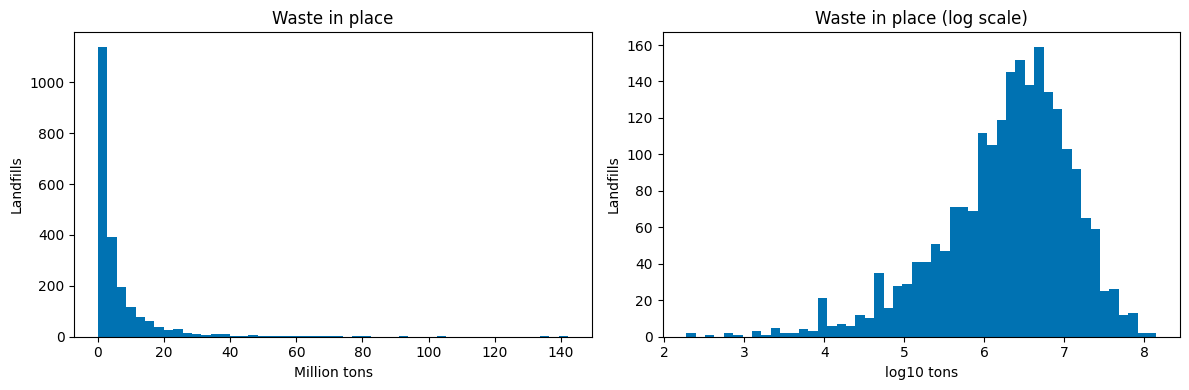

215 of 2175 landfills hold half of all waste in place
643 of 2175 landfills hold 80%


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(lf[WIP].dropna() / 1e6).plot.hist(bins=50, ax=ax[0], color='#0072B2')
ax[0].set(title='Waste in place', xlabel='Million tons', ylabel='Landfills')
np.log10(lf[WIP].dropna().clip(lower=1)).plot.hist(bins=50, ax=ax[1], color='#0072B2')
ax[1].set(title='Waste in place (log scale)', xlabel='log10 tons', ylabel='Landfills')
plt.tight_layout()
plt.show()

w = lf[WIP].dropna().sort_values(ascending=False)
share = w.cumsum() / w.sum()
print(f"{(share <= 0.5).sum()} of {len(w)} landfills hold half of all waste in place")
print(f"{(share <= 0.8).sum()} of {len(w)} landfills hold 80%")

**What the data supports, and where to be careful**

* Waste in place is heavily skewed. Most landfills sit between about 300 thousand and 30 million tons, so size comparisons below use log scales or quartiles.
* About 10% of landfills hold half of all waste. A national gap is really a story about a fairly short list of large sites.
* All 1,079 closure years after 2024 belong to open landfills, so they are expected closures rather than errors.
* About 18% of landfills have no waste in place figure and the reporting year ranges from 1965 to 2022. Waste totals are therefore lower bounds built from mixed years.
* About 12% of landfills lack usable coordinates. They are kept in every table and only drop out of the maps.

# 3. The national picture

Each landfill is placed in exactly one tier based on the most advanced project status it has:

| Tier | Rule |
|---|---|
| **Recovering** | has an operational energy project |
| **Pipeline** | has a project under construction or planned, none operational |
| **Lapsed** | had a project that shut down, nothing active now |
| **Candidate** | EPA designated candidate that never had a project |
| **Other untapped** | Future Potential, Low Potential or Unknown |

A landfill counts as **untapped** if it is in any of the last three tiers.

In [11]:
landfills = df.drop_duplicates(subset=LF_ID).set_index(LF_ID)
landfills['tier'] = df.groupby(LF_ID)[PJ_STATUS].agg(set).map(tier)
landfills['untapped'] = ~landfills['tier'].isin(['Recovering', 'Pipeline'])

# Helper columns that make state and county rollups simple sums
landfills['wip_untapped'] = landfills[WIP].where(landfills['untapped'])
landfills['flare_untapped'] = landfills[FLARED].where(landfills['untapped'])
landfills['is_candidate'] = landfills['tier'].eq('Candidate')
landfills['is_lapsed'] = landfills['tier'].eq('Lapsed')

tier_table(landfills)

,landfills,wip_Mt,pct_landfills,pct_wip
tier,,,,
Recovering,488,7192.0,18.5,53.1
Pipeline,93,1171.9,3.5,8.6
Lapsed,250,2037.0,9.5,15.0
Candidate,396,1832.2,15.0,13.5
Other untapped,1414,1319.3,53.5,9.7


In [12]:
print(pd.crosstab(landfills['tier'], landfills[STATUS], margins=True).reindex(ORDER + ['All']).to_string())

print('\nLandfills with a working collection system, by tier:')
print(landfills.loc[landfills[COLL_SYS] == 'Yes', 'tier'].value_counts().reindex(ORDER).to_string())

landfills.groupby('tier')[[COLLECTED, FLARED]].sum().reindex(ORDER).round(1)

Current Landfill Status  Closed  Open  Unknown   All
tier                                                
Recovering                   99   389        0   488
Pipeline                      6    87        0    93
Lapsed                      181    68        1   250
Candidate                    15   381        0   396
Other untapped             1046   341       27  1414
All                        1347  1266       28  2641

Landfills with a working collection system, by tier:
tier
Recovering        488
Pipeline           81
Lapsed            232
Candidate         199
Other untapped    245


,LFG Collected (mmscfd),LFG Flared (mmscfd)
tier,,
Recovering,1378.1,423.4
Pipeline,226.0,209.4
Lapsed,275.5,202.8
Candidate,177.9,177.4
Other untapped,85.1,75.4


### 3.1 Turning flared gas into an energy figure

Rather than borrowing a rule of thumb, the conversion from gas flow to electricity is derived from the dataset itself, using every operational electricity project that reports both its gas flow and its actual output.

In [13]:
el = df[(df[PJ_STATUS] == 'Operational') & (df[PJ_TYPE] == 'Electricity')]
el = el[(el['LFG Flow to Project (mmscfd)'] > 0) & (el['Actual MW Generation'] > 0)]
mw_ratio = el['Actual MW Generation'] / el['LFG Flow to Project (mmscfd)']

MW_PER_MMSCFD = mw_ratio.median()
MW_Q1, MW_Q3 = mw_ratio.quantile([.25, .75])
print(f'{len(el)} projects | MW per mmscfd: median {MW_PER_MMSCFD:.2f} (IQR {MW_Q1:.2f} to {MW_Q3:.2f})')

untapped_flare = landfills['flare_untapped'].sum()
print(f'\nFlared at untapped landfills: {untapped_flare:.1f} mmscfd')
print(f'Equivalent to about {untapped_flare * MW_PER_MMSCFD:.0f} MW '
      f'(IQR {untapped_flare * MW_Q1:.0f} to {untapped_flare * MW_Q3:.0f})')

394 projects | MW per mmscfd: median 1.85 (IQR 1.69 to 2.02)

Flared at untapped landfills: 455.7 mmscfd
Equivalent to about 845 MW (IQR 768 to 923)


In [14]:
landfills['size_band'] = pd.qcut(landfills[WIP], 4, labels=['Q1 small', 'Q2', 'Q3', 'Q4 large'])
pd.crosstab(landfills['size_band'], landfills['tier'], normalize='index').reindex(columns=ORDER).round(2)

tier,Recovering,Pipeline,Lapsed,Candidate,Other untapped
size_band,,,,,
Q1 small,0.00,0.00,0.02,0.00,0.98
Q2,0.07,0.01,0.11,0.27,0.53
Q3,0.26,0.05,0.17,0.32,0.20
Q4 large,0.56,0.10,0.15,0.14,0.06


In [15]:
by_state = landfills.groupby('State').agg(
    landfills=('tier', 'size'),
    pct_untapped=('untapped', 'mean'),
    wip=(WIP, 'sum'),
    wip_untapped=('wip_untapped', 'sum'),
    candidates=('is_candidate', 'sum'),
    lapsed=('is_lapsed', 'sum'),
    flare_untapped=('flare_untapped', 'sum'),
)
by_state['pct_untapped'] *= 100
by_state['pct_wip_untapped'] = by_state['wip_untapped'] / by_state['wip'] * 100
by_state['untapped_wip_Mt'] = by_state['wip_untapped'] / 1e6
by_state = by_state.drop(columns=['wip', 'wip_untapped'])

by_state.sort_values('untapped_wip_Mt', ascending=False).head(10).round(1)

,landfills,pct_untapped,candidates,lapsed,flare_untapped,pct_wip_untapped,untapped_wip_Mt
State,,,,,,,
CA,299,81.6,24,36,92.1,37.1,756.9
TX,129,72.1,43,13,33.6,34.3,412.3
IL,96,70.8,15,20,30.9,38.0,276.4
NY,86,75.6,2,17,11.4,52.5,272.8
OH,73,74.0,11,13,24.1,37.5,245.0
AZ,40,92.5,15,4,11.9,81.5,230.8
PA,74,54.1,6,12,36.8,30.3,224.2
GA,77,74.0,19,9,41.7,51.1,206.6
FL,75,69.3,11,7,9.0,31.7,194.1


In [16]:
focus_share = by_state.loc[FOCUS, ['untapped_wip_Mt', 'flare_untapped']].sum() / by_state[['untapped_wip_Mt', 'flare_untapped']].sum() * 100
print(f"California and Texas hold {focus_share['untapped_wip_Mt']:.1f}% of untapped waste in place "
      f"and {focus_share['flare_untapped']:.1f}% of untapped flared gas")
print('\nStates with the most candidate landfills:')
print(by_state['candidates'].sort_values(ascending=False).head(5).to_string())

California and Texas hold 22.5% of untapped waste in place and 27.6% of untapped flared gas

States with the most candidate landfills:
State
TX    43
CA    24
GA    19
IA    16
AZ    15


**National takeaways**

* 78% of landfills have no active or planned energy project, but they hold only 38% of waste in place. Recovery is concentrated at the largest sites: the Recovering tier is under a fifth of landfills but more than half of all waste.
* The gap sits in **midsize landfills**. The smallest quartile is almost entirely Other untapped (too small for a gas project), the largest quartile mostly recovers energy, and candidates cluster in the middle two quartiles.
* Gas is already being collected and burned off. About 1,245 landfills have a collection system, but fewer than 500 have an operational project. Untapped landfills flare 455.7 mmscfd, about 845 MW of potential. The derived factor of 1.85 MW per mmscfd has a tight IQR, which makes this estimate defensible.
* California and Texas rank first and second for untapped waste in place, and Texas has more candidate landfills than any other state. The rest of the notebook focuses on these two.

# 4. California vs. Texas

The two states handle organic waste very differently. California requires organics to be diverted from landfills under SB 1383, which targets a 75% reduction in landfilled organics from 2014 levels. Texas has no comparable statewide mandate. That makes them a useful pair: one leans on routing waste before it is buried, the other on capturing gas after.

In [17]:
ft = landfills[landfills['State'].isin(FOCUS)].copy()
pd.concat({s: tier_table(ft[ft['State'] == s]) for s in FOCUS}, axis=1)

CA                                      TX                             
               landfills  wip_Mt pct_landfills pct_wip landfills wip_Mt pct_landfills pct_wip
tier                                                                                         
Recovering            47  1083.2          15.7    53.1        29  728.0          22.5    60.5
Pipeline               8   198.5           2.7     9.7         7   63.2           5.4     5.3
Lapsed                36   449.8          12.0    22.1        13   87.2          10.1     7.2
Candidate             24   132.3           8.0     6.5        43  254.4          33.3    21.1
Other untapped       184   174.8          61.5     8.6        37   70.8          28.7     5.9

In [18]:
for s in FOCUS:
    d = ft[ft['State'] == s]
    print(f'\n{s}: tier by landfill status')
    print(pd.crosstab(d['tier'], d[STATUS]).reindex(ORDER).to_string())
    print(f'\n{s}: tier by collection system')
    print(pd.crosstab(d['tier'], d[COLL_SYS]).reindex(ORDER).to_string())


CA: tier by landfill status
Current Landfill Status  Closed  Open  Unknown
tier                                          
Recovering                   16    31        0
Pipeline                      2     6        0
Lapsed                       24    12        0
Candidate                     0    24        0
Other untapped              137    41        6

CA: tier by collection system
LFG Collection System In Place?   No  Shutdown  Unknown  Yes
tier                                                        
Recovering                         0         0        0   47
Pipeline                           0         0        0    8
Lapsed                             0         0        0   36
Candidate                          1         0        0   23
Other untapped                   135         1        3   45

TX: tier by landfill status
Current Landfill Status  Closed  Open  Unknown
tier                                          
Recovering                    3    26        0
Pipeline      

In [19]:
rows = {}
for s in FOCUS:
    f = ft.loc[ft['State'] == s, 'flare_untapped'].sum()
    rows[s] = {'flared_mmscfd': f,
               'MW_median': f * MW_PER_MMSCFD, 'MW_low': f * MW_Q1, 'MW_high': f * MW_Q3,
               'MMBtu_day': mmbtu_per_day(f),
               'MMBtu_day_low': mmbtu_per_day(f, 0.45), 'MMBtu_day_high': mmbtu_per_day(f, 0.55)}
display(pd.DataFrame(rows).round(1))

# Does the national conversion factor hold inside each state?
el_focus = el[el['State'].isin(FOCUS)]
(el_focus['Actual MW Generation'] / el_focus['LFG Flow to Project (mmscfd)']).groupby(el_focus['State']).describe().round(2)

,CA,TX
flared_mmscfd,92.1,33.6
MW_median,170.8,62.4
MW_low,155.3,56.7
MW_high,186.5,68.1
MMBtu_day,46618.1,17025.4
MMBtu_day_low,41956.3,15322.8
MMBtu_day_high,51279.9,18727.9


,count,mean,std,min,25%,50%,75%,max
State,,,,,,,,
CA,45.0,1.82,0.37,1.13,1.60,1.80,2.08,2.66
TX,7.0,1.74,0.17,1.45,1.63,1.82,1.88,1.90


The state level conversion factors (1.80 in California, 1.82 in Texas) sit within 3% of the national 1.85, so one factor is used throughout. Texas has only seven electricity projects to check against, so its figure is the less certain of the two.

In [20]:
ops = df[(df[PJ_STATUS] == 'Operational') & df['State'].isin(FOCUS)]
print(pd.crosstab(ops['State'], ops[PJ_TYPE], margins=True).to_string(), '\n')
ops.groupby('State')[['Actual MW Generation', 'LFG Flow to Project (mmscfd)',
                      'Current Year Emission Reductions (MMTCO2e/yr) - Direct']].sum().round(1)

Project Type Category  Direct  Electricity  Renewable Natural Gas  All
State                                                                 
CA                          2           61                      2   65
TX                          1            7                     25   33
All                         3           68                     27   98 



,Actual MW Generation,LFG Flow to Project (mmscfd),Current Year Emission Reductions (MMTCO2e/yr) - Direct
State,,,
CA,231.3,121.5,11.5
TX,15.7,101.1,9.7


This is one of the clearest contrasts in the data. **California turns its recovered gas into electricity** (61 of 65 projects). **Texas mostly cleans it up and injects it into gas pipelines as RNG** (25 of 33). Texas recovers almost as much gas as California, but it barely shows up in MW terms. For Texas, energy is better measured in MMBtu than in MW.

In [21]:
# National quartile cut points, so 'Q4 large' means the same thing in both states
for s in FOCUS:
    d = ft[ft['State'] == s]
    print(f'\n{s}')
    print(pd.crosstab(d['size_band'], d['tier'], normalize='index').reindex(columns=ORDER).round(2).to_string())


CA
tier       Recovering  Pipeline  Lapsed  Candidate  Other untapped
size_band                                                         
Q1 small         0.01      0.00    0.01       0.00            0.98
Q2               0.11      0.00    0.11       0.13            0.66
Q3               0.17      0.00    0.24       0.26            0.33
Q4 large         0.48      0.12    0.25       0.09            0.07

TX
tier       Recovering  Pipeline  Lapsed  Candidate  Other untapped
size_band                                                         
Q1 small         0.00      0.00    0.00       0.00            1.00
Q2               0.00      0.00    0.05       0.38            0.57
Q3               0.07      0.07    0.21       0.51            0.14
Q4 large         0.53      0.08    0.06       0.27            0.06


In [22]:
cols = ['Landfill Name', 'County', STATUS, WIP, COLL_SYS, COLLECTED, FLARED]
for s in FOCUS:
    for t in ['Candidate', 'Lapsed']:
        d = ft[(ft['State'] == s) & (ft['tier'] == t)].sort_values(WIP, ascending=False)
        print(f'\n{s}, {t} ({len(d)} landfills), largest ten')
        display(d[cols].head(10).round(2))


CA, Candidate (24 landfills), largest ten


,Landfill Name,County,Current Landfill Status,Waste in Place (tons),LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd)
Landfill ID,,,,,,,
311,Victorville Sanitary Landfill,San Bernardino,Open,13019199.0,Yes,0.24,0.24
188,Kirby Canyon Recycling & Disposal Facility,Santa Clara,Open,12993080.0,Yes,2.46,2.46
47,Antelope Valley Recycling and Disposal Facility,Los Angeles,Open,12645970.0,Yes,2.11,2.11
58,Bakersfield Metropolitan SLF (BENA),Kern,Open,12413341.0,Yes,1.83,1.83
314,Lancaster Landfill,Los Angeles,Open,8783782.0,Yes,1.34,1.34
270,San Timoteo Solid Waste Disposal Site,San Bernardino,Open,7407795.0,Yes,0.80,0.80
45,Anderson Landfill,Shasta,Open,5555404.0,Yes,0.97,0.97
319,West Central LF,Shasta,Open,5475597.0,Yes,1.03,1.03
150,Fairmead Solid Waste Disposal Site,Madera,Open,5473770.0,Yes,0.98,0.98



CA, Lapsed (36 landfills), largest ten


,Landfill Name,County,Current Landfill Status,Waste in Place (tons),LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd)
Landfill ID,,,,,,,
147,El Sobrante SLF,Riverside,Open,61536484.0,Yes,9.36,9.36
78,Bradley Landfill,Los Angeles,Closed,61302299.0,Yes,4.16,4.16
236,Otay LF,San Diego,Open,45777214.0,Yes,6.83,6.83
225,"Newby Island SLF Phases I, II, & III",Santa Clara,Open,35860073.0,Yes,5.14,5.14
287,Sycamore SLF,San Diego,Open,34499568.0,Yes,5.29,1.97
1780,Palos Verdes Landfill,Los Angeles,Closed,24048240.0,Yes,6.54,6.54
55,Badlands SLF,Riverside,Open,17918231.0,Yes,2.87,2.87
354,Spadra LF,Los Angeles,Closed,17268344.0,Yes,4.56,4.56
213,Milliken SLF,San Bernardino,Closed,13973400.0,Yes,2.02,2.02



TX, Candidate (43 landfills), largest ten


,Landfill Name,County,Current Landfill Status,Waste in Place (tons),LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd)
Landfill ID,,,,,,,
1511,Texas Disposal Systems LF,Travis,Open,20229498.0,Yes,1.06,1.06
2438,Itasca Landfill,Hill,Open,14452984.0,Yes,1.48,1.48
1491,Clint Landfill,El Paso,Open,12068382.0,Shutdown,0.06,0.06
1477,Golden Triangle Landfill,Jefferson,Open,11763684.0,Yes,1.22,1.22
1501,City of Laredo LF,Webb,Open,11375598.0,Yes,0.23,0.23
1811,Whispering Pines LF,Harris,Open,10248936.0,Yes,0.97,0.97
1814,City of Amarillo Landfill,Potter,Open,9795203.0,Yes,1.12,1.12
2275,Charter Waste Landfill,Ector,Open,9006846.0,No,NaN,NaN
1490,Abilene Regional Landfill,Jones,Open,8364304.0,Yes,1.45,1.45



TX, Lapsed (13 landfills), largest ten


,Landfill Name,County,Current Landfill Status,Waste in Place (tons),LFG Collection System In Place?,LFG Collected (mmscfd),LFG Flared (mmscfd)
Landfill ID,,,,,,,
1489,Sunset Farms Landfill,Travis,Closed,22281720.0,Yes,3.13,3.13
1822,Baytown Landfill,Chambers,Open,11306708.0,Yes,1.52,1.52
1473,City of Waco LF,McLennan,Open,9071718.0,Yes,1.11,1.11
1801,Trinity Oaks Landfill,Dallas,Closed,6838600.0,Yes,0.78,0.78
1470,McKinney Landfill,Collin,Closed,6539355.0,Yes,0.53,0.53
1805,City of Denton Landfill,Denton,Open,5886868.0,Yes,1.36,1.36
1778,City of Garland Castle Drive Landfill,Dallas,Closed,5507951.0,Yes,0.42,0.42
2415,Fort Worth Regional LF,Tarrant,Closed,4950848.0,Yes,0.74,0.74
1468,FM 812 Landfill,Travis,Closed,4623197.0,Yes,0.53,0.53


In [23]:
# A lapsed landfill that is still open and still flaring is the clearest restart case
restart_mask = (ft['tier'] == 'Lapsed') & (ft[STATUS] == 'Open') & (ft[FLARED] > 0)
for s in FOCUS:
    r = ft[restart_mask & (ft['State'] == s)]
    print(f'{s}: {len(r)} restart candidates flaring {r[FLARED].sum():.1f} mmscfd '
          f'(about {r[FLARED].sum() * MW_PER_MMSCFD:.0f} MW)')

CA: 12 restart candidates flaring 34.5 mmscfd (about 64 MW)
TX: 3 restart candidates flaring 4.0 mmscfd (about 7 MW)


In [24]:
def scorecard(d, state):
    u = d[d['untapped']]
    return pd.Series({
        'Landfills': len(d),
        'Waste in place (Mt)': d[WIP].sum() / 1e6,
        '% landfills untapped': d['untapped'].mean() * 100,
        '% waste untapped': u[WIP].sum() / d[WIP].sum() * 100,
        'Candidates': d['is_candidate'].sum(),
        'Lapsed': d['is_lapsed'].sum(),
        'Untapped flared (mmscfd)': u[FLARED].sum(),
        'Untapped potential (MW)': u[FLARED].sum() * MW_PER_MMSCFD,
        'Operational projects': (ops['State'] == state).sum(),
    })

pd.DataFrame({s: scorecard(ft[ft['State'] == s], s) for s in FOCUS}).round(1)

,CA,TX
Landfills,299.0,129.0
Waste in place (Mt),2038.6,1203.5
% landfills untapped,81.6,72.1
% waste untapped,37.1,34.3
Candidates,24.0,43.0
Lapsed,36.0,13.0
Untapped flared (mmscfd),92.1,33.6
Untapped potential (MW),170.8,62.4
Operational projects,65.0,33.0


**California's gap is "built, then stopped." Texas's gap is "never built."**

* In California the biggest untapped tier by waste is **Lapsed** (22% of waste in place). Large open landfills such as El Sobrante, Otay, Newby Island and Badlands once had energy projects and now flare all of their gas. Twelve open lapsed sites flare 34.5 mmscfd between them.
* In Texas the biggest untapped tier is **Candidate** (21% of waste in place, a third of all Texas landfills). These are midsize, almost all open, and about two thirds already have a collection system. The gas infrastructure exists; the energy conversion does not.
* California flares about 92 mmscfd at untapped sites (about 171 MW, or roughly 46,600 MMBtu per day). Texas flares about 34 mmscfd (about 62 MW, or roughly 17,000 MMBtu per day).

# 5. Where the gap sits

### 5.1 Does climate change how much gas a landfill gives off?

Waste decomposes more slowly in dry climates, so arid landfills should yield less gas per ton. If that were strong, location would matter as much as size. The test uses open landfills over one million tons with a working collection system, and compares gas collected per million tons of waste.

In [25]:
y = ft[(ft[COLL_SYS] == 'Yes') & (ft[COLLECTED] > 0) & (ft[WIP] > 1e6) & (ft[STATUS] == 'Open')].copy()
y['yield'] = y[COLLECTED] / (y[WIP] / 1e6)
print(y.groupby('State')['yield'].describe().round(3).to_string())

# The 98th meridian is the usual dividing line between humid east and arid west Texas
tx_y = y[(y['State'] == 'TX') & y['Longitude'].notna()].copy()
tx_y['region'] = np.where(tx_y['Longitude'] > -98, 'East TX (humid)', 'West TX (arid)')
print('\n', tx_y.groupby('region')['yield'].describe().round(3).to_string())

test = mannwhitneyu(tx_y.loc[tx_y['region'].str.startswith('East'), 'yield'],
                    tx_y.loc[tx_y['region'].str.startswith('West'), 'yield'], alternative='greater')
print(f'\nMann Whitney U (east greater than west): p = {test.pvalue:.2f}')

       count   mean    std    min    25%    50%    75%    max
State                                                        
CA      73.0  0.184  0.086  0.004  0.145  0.175  0.214  0.576
TX      59.0  0.165  0.110  0.004  0.104  0.150  0.208  0.577

                  count   mean    std    min    25%    50%    75%    max
region                                                                 
East TX (humid)   46.0  0.172  0.115  0.004  0.107  0.153  0.210  0.577
West TX (arid)    13.0  0.140  0.087  0.006  0.105  0.136  0.174  0.332

Mann Whitney U (east greater than west): p = 0.24


In [26]:
fig = px.scatter(tx_y.reset_index(), x='Longitude', y='yield', size=WIP, color='tier',
                 color_discrete_map=TIER_COLORS, hover_name='Landfill Name', log_y=True,
                 labels={'yield': 'Gas collected per million tons (mmscfd)'},
                 title='Texas: gas collected per million tons of waste, by longitude (open sites)')
fig.add_vline(x=-98, line_dash='dot', line_color='grey')
fig.show()

**The climate effect is weak.** West Texas yields about 11% less gas per ton than east Texas, but the two distributions overlap almost completely and the difference is not significant (p = 0.24, with only 13 west Texas sites). California and Texas are similarly close.

The large, low yield outliers (Laredo, El Paso, Victorville) are better explained by **partial collection**: yield here measures gas *collected*, not gas *generated*, so a site whose collection system covers only part of the landfill looks unproductive whatever its climate. This matters again in Section 7.

### 5.2 County rankings

Counties are ranked by untapped flared gas rather than by waste in place, which builds real gas output into the ranking. County tables also include the landfills that have no coordinates.

In [27]:
county = ft.groupby(['State', 'County']).agg(
    landfills=('tier', 'size'),
    untapped=('untapped', 'sum'),
    candidates=('is_candidate', 'sum'),
    lapsed=('is_lapsed', 'sum'),
    untapped_wip_Mt=('wip_untapped', lambda x: x.sum() / 1e6),
    untapped_flared=('flare_untapped', 'sum'),
)
county['MW_equiv'] = county['untapped_flared'] * MW_PER_MMSCFD
county['share_of_state_flare_%'] = county['untapped_flared'] / county.groupby(level=0)['untapped_flared'].transform('sum') * 100

for s in FOCUS:
    print(f'\n{s}: top counties by untapped flared gas')
    display(county.loc[s].sort_values('untapped_flared', ascending=False).head(10).round(1))


CA: top counties by untapped flared gas


,landfills,untapped,candidates,lapsed,untapped_wip_Mt,untapped_flared,MW_equiv,share_of_state_flare_%
County,,,,,,,,
Los Angeles,29,17,2,8,160.8,22.3,41.3,24.2
Riverside,14,13,0,3,113.1,16.5,30.6,17.9
Santa Clara,9,7,1,4,79.8,12.1,22.3,13.1
San Diego,14,11,1,4,92.2,10.7,19.8,11.6
San Bernardino,29,27,2,3,59.8,3.9,7.3,4.3
Kern,20,20,4,1,33.8,3.6,6.7,3.9
Ventura,4,3,0,2,20.2,2.9,5.5,3.2
Fresno,8,6,1,1,14.8,2.9,5.3,3.1
Shasta,6,6,2,0,12.2,2.1,3.9,2.3



TX: top counties by untapped flared gas


,landfills,untapped,candidates,lapsed,untapped_wip_Mt,untapped_flared,MW_equiv,share_of_state_flare_%
County,,,,,,,,
Travis,4,3,1,2,47.1,4.7,8.7,14.0
Tarrant,6,3,0,1,12.5,2.6,4.8,7.7
Hidalgo,4,3,1,0,16.3,2.4,4.5,7.3
Dallas,8,4,0,2,18.1,1.9,3.5,5.6
McLennan,3,3,1,1,13.4,1.8,3.3,5.2
Harris,5,3,1,1,22.5,1.5,2.8,4.6
Chambers,1,1,0,1,11.3,1.5,2.8,4.5
Hill,1,1,1,0,14.5,1.5,2.7,4.4
Jones,2,2,2,0,10.5,1.5,2.7,4.3


### 5.3 Maps

In [28]:
geo = ft[ft['Latitude'].between(17, 72) & ft['Longitude'].between(-180, -64)].copy()
geo['wip_Mt'] = geo[WIP] / 1e6
geo['marker'] = geo['wip_Mt'].fillna(0).clip(lower=1)   # display only, never used in sums
print('Mapped', len(geo), 'of', len(ft), 'California and Texas landfills')

state_map(geo, 'CA', 'California landfills by energy recovery status (marker area shows waste in place)').show()
state_map(geo, 'TX', 'Texas landfills by energy recovery status (marker area shows waste in place)').show()

Mapped 406 of 428 California and Texas landfills


### 5.4 Metro clusters

Each mapped landfill is assigned to its nearest metro center if it is within 80 km, so no landfill is counted twice where metros sit close together (Los Angeles and the Inland Empire, for example).

In [29]:
METROS = {
    'CA': {'Los Angeles': (34.05, -118.24), 'Inland Empire': (34.06, -117.30),
           'San Diego': (32.72, -117.16), 'Bay Area': (37.55, -122.10),
           'Central Valley': (36.74, -119.79)},
    'TX': {'Houston': (29.76, -95.37), 'Dallas Fort Worth': (32.78, -96.97),
           'Austin and San Antonio': (29.90, -97.95), 'El Paso': (31.76, -106.49)},
}
R_KM = 80

geo['metro'] = 'Outside metros'
for s, metros in METROS.items():
    g = geo[geo['State'] == s]
    dist = pd.DataFrame({m: haversine_km(g['Latitude'], g['Longitude'], la, lo)
                         for m, (la, lo) in metros.items()}, index=g.index)
    geo.loc[g.index, 'metro'] = np.where(dist.min(axis=1) <= R_KM, dist.idxmin(axis=1), 'Outside metros')

metro = geo[geo['metro'] != 'Outside metros'].groupby(['State', 'metro']).agg(
    landfills=('tier', 'size'),
    recovering=('tier', lambda x: (x == 'Recovering').sum()),
    candidates=('is_candidate', 'sum'),
    lapsed=('is_lapsed', 'sum'),
    untapped_flared=('flare_untapped', 'sum'),
)
metro['MW_equiv'] = metro['untapped_flared'] * MW_PER_MMSCFD
metro['MMBtu_day'] = mmbtu_per_day(metro['untapped_flared'])
metro.sort_values('untapped_flared', ascending=False).round(1)

landfills  recovering  candidates  lapsed  untapped_flared  MW_equiv  MMBtu_day
State metro                                                                                                  
CA    Los Angeles                    31          12           2       8             24.2      44.9    12255.8
      Inland Empire                  26           2           2       6             20.4      37.8    10329.0
      Bay Area                       27          11           1       8             14.3      26.6     7256.0
      San Diego                      10           3           1       3             10.4      19.2     5243.6
TX    Dallas Fort Worth              25           9           3       5              9.0      16.7     4551.5
      Austin and San Antonio          8           3           1       2              4.7       8.7     2383.8
CA    Central Valley                 10           1           2       2              4.6       8.6     2344.3
TX    Houston                        15           8           1       4              3.3       6.1     1653.1
      El Paso                         3           0           1       0              0.1       0.1       37.4

**Where the gap sits**

* **California's gap is concentrated.** Los Angeles, Riverside, Santa Clara and San Diego counties hold about two thirds of the state's untapped flared gas, and most of it comes from a handful of large lapsed sites. Los Angeles and the Inland Empire alone hold more untapped gas than all of Texas.
* **Texas's gap is spread out.** The top county, Travis, holds only about 14% of the state's untapped flare, and it takes ten counties to reach 60%. These are many small and midsize sites that would each need their own project.
* **Houston is not a hotspot.** Its metro area has many landfills but few candidates and little untapped gas, which fits a region where pipeline access and industrial buyers make landfill gas easy to sell. In Texas the larger untapped clusters are around Dallas Fort Worth and Austin.

# 6. How each state got here

The current file records a start date for every project and a shutdown date for almost every closed one, so the number of projects active in any year can be rebuilt without the historical files. This counts projects, not capacity, and only includes projects still listed in today's database.

In [30]:
pj = df[df['State'].isin(FOCUS) & df[PJ_STATUS].isin(['Operational', 'Shutdown'])].copy()
pj['start_yr'] = pj['Project Start Date'].dt.year
pj['shut_yr'] = pj['Project Shutdown Date'].dt.year

pj.groupby(['State', PJ_STATUS]).agg(
    projects=('Project ID', 'size'),
    pct_with_start=('start_yr', lambda x: x.notna().mean() * 100),
    pct_with_shutdown=('shut_yr', lambda x: x.notna().mean() * 100)).round(0)

projects  pct_with_start  pct_with_shutdown
State Current Project Status                                             
CA    Operational                   65           100.0                2.0
      Shutdown                     105           100.0               97.0
TX    Operational                   33           100.0                0.0
      Shutdown                      36           100.0              100.0

In [31]:
rows = []
for yr in range(1985, 2025):
    active = pj[(pj['start_yr'] <= yr) & (pj['shut_yr'].isna() | (pj['shut_yr'] > yr))]
    for (s, t), g in active.groupby(['State', PJ_TYPE]):
        rows.append({'year': yr, 'State': s, 'type': t, 'active': len(g)})
ts = pd.DataFrame(rows)

totals = ts.groupby(['year', 'State'], as_index=False)['active'].sum()
fig = px.line(totals, x='year', y='active', color='State', color_discrete_map=STATE_COLORS,
              labels={'active': 'Active projects', 'year': ''},
              title='Active landfill gas energy projects, rebuilt from start and shutdown dates')
for yr, label, shift in [(2016, 'SB 1383 enacted', 10), (2022, 'SB 1383 enforcement', 28)]:
    fig.add_vline(x=yr, line_dash='dot', line_color='grey')
    fig.add_annotation(x=yr, y=1, yref='paper', text=label, showarrow=False, yshift=shift)
fig.show()

px.area(ts, x='year', y='active', color='type', facet_col='State', color_discrete_map=TYPE_COLORS,
        labels={'active': 'Active projects', 'year': ''},
        title='Active projects by type').show()

In [32]:
net = pd.concat([pj.groupby(['State', 'start_yr']).size().rename('starts'),
                 pj.groupby(['State', 'shut_yr']).size().rename('shutdowns')], axis=1).fillna(0)
net.index = net.index.set_names(['State', 'year'])
net['net'] = net['starts'] - net['shutdowns']
net = net.reset_index()
net[net['year'] >= 2000].pivot(index='year', columns='State', values='net').fillna(0).astype(int).T

year,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
State,,,,,,,,,,,,,,,,,,,,,,,,,
CA,1,2,2,8,5,-3,6,3,-2,1,-1,1,-2,2,5,-3,-4,-1,-6,-3,0,0,1,-2,0
TX,2,0,1,8,3,2,-1,-1,3,5,2,1,1,0,1,1,-3,1,1,-2,1,0,-1,0,3


In [33]:
lapsed_ids = ft.index[ft['tier'] == 'Lapsed']
lp = pj[pj[LF_ID].isin(lapsed_ids)]
print(lp.groupby('State')['shut_yr'].describe().round(0).to_string())

px.histogram(lp, x='shut_yr', color='State', barmode='group', nbins=30, color_discrete_map=STATE_COLORS,
             labels={'shut_yr': 'Shutdown year'},
             title='When projects at now lapsed landfills shut down').show()

restart_ids = ft.index[restart_mask]
display(pj[pj[LF_ID].isin(restart_ids)]
        [['Landfill Name', 'State', PJ_TYPE, 'LFG Energy Project Type', 'start_yr', 'shut_yr']]
        .sort_values('shut_yr'))

       count    mean   std     min     25%     50%     75%     max
State                                                             
CA      61.0  2008.0  11.0  1975.0  2003.0  2010.0  2015.0  2023.0
TX      19.0  2012.0   5.0  2004.0  2008.0  2013.0  2016.0  2020.0


,Landfill Name,State,Project Type Category,LFG Energy Project Type,start_yr,shut_yr
229,City of Lompoc SLF,CA,Electricity,Reciprocating Engine,1985,1985.0
210,California Street LF,CA,Electricity,Reciprocating Engine,2003,2004.0
2943,City of Waco LF,TX,Electricity,Steam Turbine,2004,2007.0
379,"Newby Island SLF Phases I, II, & III",CA,Electricity,Reciprocating Engine,1984,2008.0
2921,City of Denton Landfill,TX,Direct,Boiler,2005,2008.0
541,Woodville Landfill,CA,Electricity,Reciprocating Engine,2000,2009.0
380,"Newby Island SLF Phases I, II, & III",CA,Electricity,Reciprocating Engine,1989,2010.0
272,El Sobrante SLF,CA,Electricity,Reciprocating Engine,2004,2010.0
491,Sycamore SLF,CA,Electricity,Gas Turbine,1988,2010.0
329,Lamb Canyon Sanitary Landfill,CA,Electricity,Microturbine,2010,2011.0


In [34]:
# Did landfills that lost an electricity project gain an RNG project afterwards?
el_shut = (pj[(pj[PJ_TYPE] == 'Electricity') & pj['shut_yr'].notna()]
           .groupby(LF_ID).agg(State=('State', 'first'), last_shutdown=('shut_yr', 'max')))
rng_ids = df.loc[df['State'].isin(FOCUS) & (df[PJ_TYPE] == 'Renewable Natural Gas') &
                 df[PJ_STATUS].isin(['Operational', 'Construction', 'Planned']), LF_ID].unique()
el_shut['rng_successor'] = el_shut.index.isin(rng_ids)

succ = pd.crosstab(el_shut['State'], el_shut['rng_successor'], margins=True)
succ['% with RNG successor'] = (succ[True] / succ['All'] * 100).round(0)
succ

rng_successor,False,True,All,% with RNG successor
State,,,,
CA,47,8,55,15.0
TX,11,7,18,39.0
All,58,15,73,21.0


**What the timeline shows**

* **California peaked in 2014** at about 85 active projects and has since fallen to about 67. The decline started in 2015, a year *before* SB 1383 was enacted, so the mandate cannot be credited or blamed for it.
* **Texas started late and then switched technology.** Projects took off around 2003 and have held at about 30 to 33 since 2010. Underneath that flat total, electricity projects fell from about 26 to about 8 while RNG rose from about 3 to about 25.
* **California's lapsed sites are electricity projects that were never replaced.** The restart cases (Newby Island, El Sobrante, Badlands, Otay, Sycamore) are all reciprocating engines or turbines that shut down between 2008 and 2023. Only 15% of California landfills that lost an electricity project gained an RNG successor, against 39% in Texas.

Possible reasons include aging engines, expiring power contracts, tighter air rules on engines in Southern California and the economics of RNG. This dataset cannot separate them, so they are listed here as hypotheses rather than findings. What the data does show is that the gas at these sites kept coming after the projects stopped.

# 7. Where to build, 2025 to 2050

Today's flare rankings favor sites that are already declining. To guide where projects should go, gas output has to be projected forward.

There is no gas history per site in this file, only a single snapshot, so a machine learning forecast would have nothing to learn from and no way to be checked. Instead this section uses **LandGEM**, EPA's first order decay model for landfill gas. Each year's waste generates methane that declines exponentially as it ages:

$$Q_t = \sum_{i} k \, L_0 \, M_i \, e^{-k (t - t_i)}$$

where $M_i$ is the waste placed in year $t_i$, $k$ is the decay rate and $L_0$ is the methane generation potential per ton. The model is then checked against the gas each site actually reports collecting.

In [35]:
YEARS_OUT = np.arange(2025, 2051)

# EPA AP-42 inventory defaults (Section 2.4)
K_CONV = 0.04            # per year, conventional climate
K_ARID = 0.02            # per year, areas with under 25 inches of rain
L0 = 100                 # m3 of methane per metric ton of waste
COLLECT_EFF = 0.75       # typical collection efficiency, tested from 0.60 to 0.85

SHORT_TON_TO_MG = 0.9072 # LMOP reports short tons
M3_TO_SCF = 35.3147

**Reconstructing each site's waste history.** The file gives total waste in place at one point in time. I assume waste arrived at a constant rate from opening to that reporting year and keeps arriving at the same rate until the expected closure year. Sites missing the opening year, closure year or waste in place cannot be modeled.

In [36]:
sites = ft.copy()
sites['wip_yr_imputed'] = sites['Waste in Place Year'].isna()
sites['wip_yr'] = sites['Waste in Place Year'].fillna(2022)
sites['open_yr'] = sites['Year Landfill Opened']
sites['close_yr'] = sites['Landfill Closure Year']

ok = (sites[WIP].notna() & sites['open_yr'].notna() & sites['close_yr'].notna()
      & (sites['wip_yr'] >= sites['open_yr']))
excluded = sites[~ok]
sites = sites[ok].copy()
sites['rate_Mg'] = sites[WIP] * SHORT_TON_TO_MG / (sites['wip_yr'] - sites['open_yr'] + 1)

# Arid classification: west of the 98th meridian in Texas, desert counties in California
CA_ARID = {'San Bernardino', 'Riverside', 'Kern', 'Imperial', 'Inyo', 'Kings'}
sites['arid'] = np.where(sites['State'] == 'TX', sites['Longitude'] < -98, sites['County'].isin(CA_ARID))

print(f'{len(sites)} of {len(ft)} sites modeled ({sites["wip_yr_imputed"].sum()} with an imputed reporting year)')
print('\nTiers of the excluded sites:')
print(excluded['tier'].value_counts().to_string())

300 of 428 sites modeled (61 with an imputed reporting year)

Tiers of the excluded sites:
tier
Other untapped    123
Lapsed              3
Recovering          1
Candidate           1


In [37]:
def landgem(rate_mg, open_yr, close_yr, k, l0, years, l0_future_mult=1.0, cut_year=2025):
    # Methane generated (m3 per year) in each of `years`.
    # Waste placed from cut_year onward has its L0 scaled by l0_future_mult (diversion scenario).
    years = np.asarray(years, dtype=float)
    q = np.zeros(len(years))
    last = int(min(close_yr, years.max()))   # waste placed after the last year cannot contribute
    for y_dep in range(int(open_yr), last + 1):
        l0_y = l0 * (l0_future_mult if y_dep >= cut_year else 1.0)
        age = years - y_dep - 0.5
        q += np.where(age > 0, k * l0_y * rate_mg * np.exp(-k * age), 0.0)
    return q


def to_mmscfd(ch4_m3_per_yr):
    # Methane volume to total landfill gas flow
    return ch4_m3_per_yr / CH4_FRAC * M3_TO_SCF / 365 / 1e6


def project(site_df, years, k_conv=K_CONV, k_arid=K_ARID, l0=L0, l0_mult=None):
    # Generated landfill gas (mmscfd), one row per site and one column per year
    l0_mult = l0_mult or {}
    out = {}
    for lid, r in site_df.iterrows():
        k = k_arid if r['arid'] else k_conv
        out[lid] = to_mmscfd(landgem(r['rate_Mg'], r['open_yr'], r['close_yr'], k, l0, years,
                                     l0_mult.get(r['State'], 1.0)))
    return pd.DataFrame(out, index=np.asarray(years)).T


def calibrate(k_conv=K_CONV, k_arid=K_ARID, l0=L0):
    # Compares modeled collectable gas in 2023 with what each site reports collecting
    cal = sites[(sites[COLL_SYS] == 'Yes') & (sites[COLLECTED] > 0)].copy()
    cal['modeled'] = project(cal, [2023], k_conv, k_arid, l0)[2023] * COLLECT_EFF
    cal = cal[cal['modeled'] > 0]   # sites whose waste history gives no gas yet cannot be compared
    cal['ratio'] = cal[COLLECTED] / cal['modeled']
    return cal, cal.groupby('State')['ratio'].median()

### 7.1 Checking the model against reported collection

In [38]:
cal, CAL = calibrate()
print(cal.groupby('State')['ratio'].describe(percentiles=[.25, .5, .75]).round(2).to_string())

rho = spearmanr(cal['modeled'], cal[COLLECTED])
print(f'\nSpearman rank correlation, modeled vs reported: {rho.statistic:.2f} (p = {rho.pvalue:.1e}, n = {len(cal)})')

fig = px.scatter(cal.reset_index(), x='modeled', y=COLLECTED, color='State', color_discrete_map=STATE_COLORS,
                 log_x=True, log_y=True, hover_name='Landfill Name',
                 labels={'modeled': 'Modeled collectable gas, 2023 (mmscfd)', COLLECTED: 'Reported collected (mmscfd)'},
                 title='Reported vs. modeled landfill gas collection')
fig.add_shape(type='line', x0=0.01, y0=0.01, x1=50, y1=50, line=dict(dash='dot', color='grey'))
fig.show()

       count  mean   std   min   25%   50%   75%    max
State                                                  
CA     141.0  2.10  3.03  0.03  0.73  0.99  1.64  17.68
TX      79.0  1.04  2.13  0.01  0.50  0.64  0.96  17.00

Spearman rank correlation, modeled vs reported: 0.80 (p = 3.1e-50, n = 220)


**The model holds up well enough to rank sites.**

* The rank correlation of about 0.80 across 220 sites means LandGEM orders sites by gas output well.
* In California the median ratio of reported to modeled gas is about 0.99, so EPA's defaults fit without adjustment.
* In Texas sites collect about a third less than modeled (median about 0.64). That fits the partial collection pattern from Section 5.1 more than any difference in the waste itself.
* Small sites sit above the line, meaning the constant arrival assumption fits large landfills better than small ones. The rankings below are driven by large sites, so this has little effect on them.

Each state's median ratio is used as a calibration factor in the projections that follow.

### 7.2 Projecting untapped sites to 2050

In [39]:
unt = sites[sites['untapped']].copy()

base = project(unt, YEARS_OUT) * COLLECT_EFF
base = base.mul(unt['State'].map(CAL), axis=0)

unt['lfg_2025'] = base[2025]
unt['lfg_2050'] = base[2050]
unt['avg_MW_equiv'] = base.mean(axis=1) * MW_PER_MMSCFD
unt['cum_MMBtu_2025_2050'] = mmbtu_per_day(base).sum(axis=1) * 365

# Cross check: modeled 2025 gas against what these sites report flaring today
pd.DataFrame({'modeled_2025_mmscfd': unt.groupby('State')['lfg_2025'].sum(),
              'reported_flared_mmscfd': unt.groupby('State')[FLARED].sum()}).round(1)

,modeled_2025_mmscfd,reported_flared_mmscfd
State,,
CA,104.1,91.4
TX,56.7,33.6


**A diversion scenario.** If organics are kept out of landfills, the waste that does arrive has less methane potential. California's scenario halves $L_0$ for waste placed from 2025 onward, a simple stand in for SB 1383 rather than a detailed policy model. Texas is left unchanged since it has no comparable mandate.

In [40]:
SCENARIO = {'CA': 0.5, 'TX': 1.0}

div = project(unt, YEARS_OUT, l0_mult=SCENARIO) * COLLECT_EFF
div = div.mul(unt['State'].map(CAL), axis=0)

traj = pd.concat({
    'Baseline': base.groupby(unt['State']).sum(),
    'Diversion': div.groupby(unt['State']).sum(),
}, names=['scenario', 'State']).stack().rename('mmscfd').reset_index().rename(columns={'level_2': 'year'})

px.line(traj, x='year', y='mmscfd', color='State', line_dash='scenario', color_discrete_map=STATE_COLORS,
        labels={'mmscfd': 'Collectable landfill gas (mmscfd)', 'year': ''},
        title='Collectable gas at untapped landfills, 2025 to 2050').show()

traj[traj['year'].isin([2025, 2035, 2050])].pivot_table(index=['State', 'scenario'], columns='year', values='mmscfd').round(1)

year              2025  2035  2050
State scenario                    
CA    Baseline   104.1  98.6  84.9
      Diversion  104.1  86.7  65.7
TX    Baseline    56.7  57.4  53.6
      Diversion   56.7  57.4  53.6

The two states head in opposite directions. **California's untapped landfill gas shrinks**, slowly at baseline and faster with diversion. **Texas's grows** until around 2040 because its open sites keep filling and nothing is diverted. The gap between California's two lines is energy that diversion moves out of landfills. It does not disappear; it has to be captured upstream by a digester or another conversion route.

### 7.3 How much confidence each site deserves

A projection is only as good as the evidence behind it. Each site is labeled by whether its measured gas agrees with the model, and then given a priority that combines that confidence with how ready the site is for a project.

| Confidence | Rule |
|---|---|
| **Corroborated** | reported collection is between half and double the model |
| **Check** | reported collection and the model disagree by more than 2x |
| **Model only** | no collection system or no measurement to compare with |

In [41]:
unt['model_2023'] = project(unt, [2023])[2023] * COLLECT_EFF * unt['State'].map(CAL)
unt['obs_ratio'] = unt[COLLECTED] / unt['model_2023']


def confidence(r):
    if pd.isna(r['obs_ratio']) or r[COLL_SYS] != 'Yes':
        return 'Model only'
    if 0.5 <= r['obs_ratio'] <= 2:
        return 'Corroborated'
    return 'Check'


def priority(r):
    ready = r[STATUS] == 'Open' and r[COLL_SYS] == 'Yes'
    if r['confidence'] == 'Corroborated' and ready:
        return 'A: Build now'
    if r['confidence'] == 'Corroborated':
        return 'B: Strong, needs work'
    if r['confidence'] == 'Check':
        return 'C: Verify collection'
    return 'D: Model only, survey first'


unt['confidence'] = unt.apply(confidence, axis=1)
unt['priority'] = unt.apply(priority, axis=1)
pd.crosstab(unt['State'], unt['priority'], margins=True)

priority,A: Build now,"B: Strong, needs work",C: Verify collection,"D: Model only, survey first",All
State,,,,,
CA,29,18,40,44,131
TX,22,11,13,33,79
All,51,29,53,77,210


In [42]:
show = ['Landfill Name', 'County', 'tier', 'priority', 'lfg_2025', 'lfg_2050', 'avg_MW_equiv', 'cum_MMBtu_2025_2050']
for s in FOCUS:
    print(f'\n{s}: top 15 opportunities, ordered by priority then cumulative energy')
    display(unt[unt['State'] == s].sort_values(['priority', 'cum_MMBtu_2025_2050'], ascending=[True, False])[show]
            .head(15).round(2))


CA: top 15 opportunities, ordered by priority then cumulative energy


,Landfill Name,County,tier,priority,lfg_2025,lfg_2050,avg_MW_equiv,cum_MMBtu_2025_2050
Landfill ID,,,,,,,,
147,El Sobrante SLF,Riverside,Lapsed,A: Build now,11.78,15.70,25.76,66738228.13
287,Sycamore SLF,San Diego,Lapsed,A: Build now,6.80,7.18,13.01,33704185.62
236,Otay LF,San Diego,Lapsed,A: Build now,9.14,4.00,12.48,32329799.40
225,"Newby Island SLF Phases I, II, & III",Santa Clara,Lapsed,A: Build now,5.35,2.85,8.29,21474899.36
188,Kirby Canyon Recycling & Disposal Facility,Santa Clara,Candidate,A: Build now,3.63,4.24,7.38,19113570.32
55,Badlands SLF,Riverside,Lapsed,A: Build now,2.85,3.35,5.78,14964131.55
58,Bakersfield Metropolitan SLF (BENA),Kern,Candidate,A: Build now,2.53,3.00,5.61,14521582.49
191,Lamb Canyon Sanitary Landfill,Riverside,Lapsed,A: Build now,2.28,2.73,4.67,12102402.19
294,Toland Road SLF,Ventura,Lapsed,A: Build now,2.40,1.63,4.22,10920460.15



TX: top 15 opportunities, ordered by priority then cumulative energy


,Landfill Name,County,tier,priority,lfg_2025,lfg_2050,avg_MW_equiv,cum_MMBtu_2025_2050
Landfill ID,,,,,,,,
1477,Golden Triangle Landfill,Jefferson,Candidate,A: Build now,2.40,1.89,4.62,11964271.22
2438,Itasca Landfill,Hill,Candidate,A: Build now,2.27,2.52,4.48,11597420.56
1822,Baytown Landfill,Chambers,Lapsed,A: Build now,2.01,1.37,3.60,9319941.19
1811,Whispering Pines LF,Harris,Candidate,A: Build now,1.64,1.60,3.20,8289881.85
2437,ECD Landfill,Ellis,Candidate,A: Build now,1.32,1.56,2.70,7003538.86
2441,El Centro Landfill,Nueces,Candidate,A: Build now,1.14,1.56,2.57,6661573.72
12207,Brownsville Municipal Landfill,Cameron,Candidate,A: Build now,1.20,1.34,2.38,6154408.32
1814,City of Amarillo Landfill,Potter,Candidate,A: Build now,1.09,1.34,2.28,5898689.85
21133,La Gloria Ranch Landfill,Hidalgo,Candidate,A: Build now,0.66,1.63,2.20,5689781.10


In [43]:
a = unt[unt['priority'] == 'A: Build now']
summary_a = a.groupby('State').agg(sites=('tier', 'size'), lfg_2025=('lfg_2025', 'sum'),
                                   avg_MW=('avg_MW_equiv', 'sum'), cum_MMBtu=('cum_MMBtu_2025_2050', 'sum'))
summary_a['share_of_state_untapped_gas_%'] = summary_a['lfg_2025'] / unt.groupby('State')['lfg_2025'].sum() * 100
summary_a.round(1)

,sites,lfg_2025,avg_MW,cum_MMBtu,share_of_state_untapped_gas_%
State,,,,,
CA,29,65.6,122.4,316967145.9,63.0
TX,22,23.2,44.9,116264810.9,41.0


In [44]:
county_rank = (unt.groupby(['State', 'County'])
                  .agg(sites=('tier', 'size'),
                       build_now=('priority', lambda x: (x == 'A: Build now').sum()),
                       avg_MW=('avg_MW_equiv', 'sum'),
                       cum_MMBtu=('cum_MMBtu_2025_2050', 'sum'))
                  .sort_values('cum_MMBtu', ascending=False))
county_rank.groupby(level=0).head(10).round(0)

sites  build_now  avg_MW    cum_MMBtu
State County                                               
CA    Riverside           9          3    39.0  101672703.0
      San Diego           9          2    27.0   69509022.0
      Santa Clara         6          3    21.0   53582472.0
      Los Angeles        12          2    20.0   50950297.0
      San Bernardino     22          2    12.0   31150045.0
TX    Travis              3          0    12.0   31073953.0
CA    Kern               11          2    11.0   29169157.0
TX    Jefferson           2          1     6.0   15683378.0
CA    Tulare              3          0     5.0   13573787.0
      Ventura             2          1     5.0   13506337.0
      Kings               3          2     5.0   13187295.0
      Shasta              3          2     5.0   12947517.0
TX    Hill                1          1     4.0   11597421.0
      Ellis               2          1     4.0   11359752.0
      Hidalgo             3          1     4.0   11153345.0
      Lamar               2          0     4.0    9387301.0
      Chambers            1          1     4.0    9319941.0
      Harris              3          1     4.0    9141050.0
      El Paso             3          0     4.0    9099301.0
      Newton              1          0     3.0    8379337.0

### 7.4 How the forward view changes the ranking

In [45]:
cmp = unt[['Landfill Name', 'State', 'confidence', FLARED, 'cum_MMBtu_2025_2050']].copy()
cmp['rank_today'] = cmp.groupby('State')[FLARED].rank(ascending=False)
cmp['rank_2050'] = cmp.groupby('State')['cum_MMBtu_2025_2050'].rank(ascending=False)
cmp['places_gained'] = cmp['rank_today'] - cmp['rank_2050']

for s in FOCUS:
    c = cmp[cmp['State'] == s]
    overlap = len(set(c.index[c['rank_today'] <= 15]) & set(c.index[c['rank_2050'] <= 15]))
    print(f'\n{s}: {overlap} of the top 15 sites are the same today and through 2050. Biggest climbers:')
    display(c.sort_values('places_gained', ascending=False).head(5).round(2))


CA: 10 of the top 15 sites are the same today and through 2050. Biggest climbers:


,Landfill Name,State,confidence,LFG Flared (mmscfd),cum_MMBtu_2025_2050,rank_today,rank_2050,places_gained
Landfill ID,,,,,,,,
311,Victorville Sanitary Landfill,CA,Check,0.24,12059767.81,66.0,10.0,56.0
179,Allied Imperial Landfill,CA,Check,0.02,4646848.98,79.5,26.0,53.5
260,Ridgecrest-Inyokern SLF,CA,Check,0.13,3418490.16,71.0,32.0,39.0
227,North County SLF,CA,Check,0.38,7652831.73,52.0,15.0,37.0
60,Barstow Sanitary Landfill,CA,Model only,0.12,2498818.11,72.0,39.0,33.0



TX: 9 of the top 15 sites are the same today and through 2050. Biggest climbers:


,Landfill Name,State,confidence,LFG Flared (mmscfd),cum_MMBtu_2025_2050,rank_today,rank_2050,places_gained
Landfill ID,,,,,,,,
2397,Newton County Landfill,TX,Check,0.03,8379336.84,45.0,6.0,39.0
1491,Clint Landfill,TX,Model only,0.06,7525623.19,44.0,8.0,36.0
1501,City of Laredo LF,TX,Check,0.23,6382451.82,36.0,12.0,24.0
2398,Paris Landfill,TX,Check,0.13,4747178.81,42.0,21.0,21.0
2273,Maloy Landfill,TX,Check,0.08,4415132.77,43.0,25.0,18.0


### 7.5 Sensitivity to the decay parameters

The absolute numbers depend on $k$ and $L_0$, so the ranking is rerun under EPA's regulatory defaults ($k$ = 0.05, $L_0$ = 170) and with slower decay everywhere ($k$ = 0.02). Calibration is redone each time, and the check is how much of the baseline top 15 survives.

In [46]:
def top15(projection, site_df):
    cum = mmbtu_per_day(projection).sum(axis=1) * 365
    return {s: set(cum[site_df['State'] == s].nlargest(15).index) for s in FOCUS}

baseline_top = top15(base, unt)
rows = []
for label, kc, ka, l0 in [('AP-42 inventory (baseline)', 0.04, 0.02, 100),
                          ('Regulatory defaults', 0.05, 0.05, 170),
                          ('Slow decay everywhere', 0.02, 0.02, 100)]:
    _, cal_s = calibrate(kc, ka, l0)
    proj = project(unt, YEARS_OUT, kc, ka, l0) * COLLECT_EFF
    proj = proj.mul(unt['State'].map(cal_s), axis=0)
    tops = top15(proj, unt)
    for s in FOCUS:
        rows.append({'scenario': label, 'State': s,
                     'collectable_2025_mmscfd': proj.loc[unt['State'] == s, 2025].sum(),
                     'avg_MW': proj.loc[unt['State'] == s].mean(axis=1).sum() * MW_PER_MMSCFD,
                     'top15_overlap_with_baseline': len(tops[s] & baseline_top[s])})

pd.DataFrame(rows).pivot(index='scenario', columns='State').round(1)

collectable_2025_mmscfd       avg_MW        top15_overlap_with_baseline    
State                                           CA    TX     CA     TX                          CA  TX
scenario                                                                                              
AP-42 inventory (baseline)                   104.1  56.7  177.5  104.8                          15  15
Regulatory defaults                          120.1  61.4  198.6  108.0                          13  12
Slow decay everywhere                        109.8  59.9  200.4  118.4                          12  12

**Where to build**

* **California's build now list is led by restarts.** The top five (El Sobrante, Otay, Sycamore, Newby Island and Badlands) are all lapsed, open, collecting gas, and measured close to what the model predicts. El Sobrante alone averages about 26 MW through 2050, more than the top three Texas sites combined. Riverside County leads the state.
* **Texas's build now list is led by first projects.** The strongest corroborated sites are on the Gulf Coast (Golden Triangle, Baytown, Whispering Pines) and around Dallas Fort Worth (Itasca, ECD, Denton), with further sites in the Panhandle and South Texas. Texas's largest site by volume, Texas Disposal Systems, lands in *Check* because it reports well under half its modeled gas.
* **52 sites qualify as build ready**, averaging about 151 MW between them. They cover about 60% of California's untapped gas but only about 39% of Texas's. California's next step is restarting what it already built; Texas's is measuring before it builds.
* **The biggest climbers deserve caution.** Sites that rise most once the ranking looks forward (Victorville, Allied Imperial, Ridgecrest and Barstow in California; Clint and Laredo in Texas) are mostly arid and weakly measured. Their climb comes from the model rather than from evidence, so they are flagged for verification rather than recommended.

# 8. What this means for waste routing

Landfill gas capture is recovery at the end of the pipe. It starts only after organic waste has been buried, it captures part of the methane that waste produces, and as Sections 4 and 6 show, it can stop while the gas keeps coming. Both states' gaps trace back to the same upstream decision: organic waste went to a landfill instead of to a conversion pathway suited to it.

* **California** already requires organics to be diverted. The open question there is which pathway each diverted stream should go to: anaerobic digestion for wet food waste, other routes for drier or oil rich streams. Section 7 shows that this diverted energy leaves the landfill system, so it has to be captured somewhere else.
* **Texas** has no comparable mandate. Its near term opportunity is converting flared gas at candidate sites, where its RNG experience offers a proven model. The longer term opportunity is routing organics before they reach a landfill at all.

In both states the decision that sets how much energy is ultimately recovered is pathway selection at the point where waste is generated, a choice operators still make largely by experience. That decision is the focus of my related work on data driven conversion pathway selection for mixed waste streams.

# 9. Assumptions and limitations

| Parameter | Value | Source | Effect |
|---|---|---|---|
| MW per mmscfd | 1.85 (IQR 1.69 to 2.02) | Derived from 394 operational LMOP electricity projects | About ±9% on every MW figure |
| State factor check | CA 1.80, TX 1.82 | Same method within each state | National factor within 3% |
| Landfill gas methane share | 50% (45% to 55%) | Typical landfill gas composition | About ±10% on MMBtu figures |
| Methane higher heating value | 1,012 Btu/scf | Standard property | Fixed |
| Decay rate $k$ | 0.04 per year, 0.02 arid | EPA AP-42 Section 2.4 inventory defaults | Tested in Section 7.5 |
| Methane potential $L_0$ | 100 m³ per metric ton | EPA AP-42 Section 2.4 inventory default | Tested in Section 7.5 |
| Collection efficiency | 75% | EPA AP-42 typical value | Scales projections, absorbed by calibration |
| Calibration factor | CA about 0.99, TX about 0.64 | Median of reported vs modeled collection | Applied per state |
| Waste arrival | Constant rate from opening to closure | Analyst assumption | Fits large sites better than small |
| Diversion scenario | CA future $L_0$ halved from 2025 | Simplified stand in for SB 1383 | Illustrative only |
| Untapped | No operational, construction or planned project | Analyst definition | See Section 3 |
| Metro assignment | Nearest metro within 80 km | Analyst choice | Affects Section 5.4 only |

**Limitations**

* Flaring and collection figures are self reported and reflect a single recent year. Where a collection system covers only part of a site, today's flare understates its potential.
* About 18% of landfills lack waste in place and the reporting year varies from 1965 to 2022, so waste totals are lower bounds.
* About 12% of landfills lack coordinates. They are included in every table but missing from the maps.
* The project timeline counts projects rather than capacity, and only covers projects still listed in today's database.
* The causes of California's project shutdowns are not observable in this data.
* MW figures assume the gas is used to generate electricity. For RNG, which dominates in Texas, the MMBtu figures are the more meaningful measure.
* LandGEM is a screening model. A site level decision would need on site gas measurements and a collection system survey.

# 10. References

* U.S. EPA, Landfill Methane Outreach Program (LMOP), Landfill and Landfill Gas Energy Project Database, September 2024. https://www.epa.gov/lmop/landfill-technical-data
* U.S. EPA, AP-42: Compilation of Air Emissions Factors, Section 2.4, Municipal Solid Waste Landfills. https://www.epa.gov/air-emissions-factors-and-quantification/ap-42-compilation-air-emissions-factors-stationary-sources
* U.S. EPA, Landfill Gas Emissions Model (LandGEM). https://www.epa.gov/land-research/landfill-gas-emissions-model-landgem
* CalRecycle, California's Short Lived Climate Pollutant Reduction Strategy (SB 1383). https://calrecycle.ca.gov/organics/slcp/